# Chapter 37 — Crypto Derivatives

Every number in the chapter's worked examples, tables and figure, recomputed in order. The code uses **NumPy, SciPy and
Matplotlib**. Nothing in the chapter is simulated, so every figure reproduces exactly.

Each figure is printed beside the chapter's value with `ok` or `DIFFERS`; the last cell lists any that differ.

| Section | What it reproduces | Example / Figure |
|---|---|---|
| 1 | The basis trade, transplanted: annualized basis, leverage and return on capital | 37.1 |
| 2 | A hedged trade that a rally can close: margin calls, and the chance of a 20% rally | 37.2 |
| 3 | Staking as a dividend: forwards at different staking yields; the issuance yield | 37.3 |
| 4 | Funding every eight hours, annualized | 37.4 |
| 5 | A liquidation cascade with published barriers | 37.5 |
| 6 | Black's model on the traded futures price against a forward built from spot | 37.6 |
| 7 | What a 70% volatility costs: straddles and the variance premium | 37.7 |
| 8 | The inverse contract: coin and dollar P&L, gamma, equity, and the numeraire | 37.8 |
| 9 | A miner's break-even and the difficulty adjustment | 37.9 |
| 10 | Providing liquidity is selling gamma: impermanent loss and the fee yield | 37.10, Figure 37.1 |
| 11 | What a stablecoin's discount was pricing | 37.11 |

The helpers below are used throughout. `show` prints a computed figure beside the chapter's, with a tolerance
that matches the printed rounding.

In [1]:
from math import exp, log, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.integrate import quad

N = norm.cdf
BAD = []

# The book's figure palette, from preamble.tex: exampleframe for the primary series,
# snapshotframe for the contrast one, told apart by dash pattern as well as color.
BLUE, AMBER = "#28466E", "#78551E"
plt.rcParams.update({"figure.figsize": (6.4, 3.4), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 9})


def show(label, got, printed, tol=5e-4):
    """A figure beside the chapter's. `tol` is absolute and matches the printed rounding."""
    ok = abs(got - printed) <= tol
    if not ok:
        BAD.append(label)
    print("%-52s %14.4f   book %13.4f   %s" % (label, got, printed, "ok" if ok else "DIFFERS"))

## 1. The basis trade, transplanted — Example 37.1

Spot bitcoin at \$60,000 and the three-month futures price at \$61,800, with financing at 5%. The chapter compounds the
quarterly basis to annualize it, $(1+b)^4 - 1$, and the excess over the cost of carry is what a cash-and-carry trade
earns. On margin, the excess return is divided by the share of the notional posted.

In [2]:
S, F, R_FIN = 60000.0, 61800.0, 0.05
basis = F / S - 1
show("quarterly basis (%)", 100 * basis, 3.00, 5e-3)
annual = (1 + basis) ** 4 - 1
show("annualized basis, compounded (%)", 100 * annual, 12.55, 5e-3)
excess = annual - R_FIN
show("excess over the cost of carry (%)", 100 * excess, 7.55, 5e-3)
for margin, lev, roc in ((0.50, 2.0, 15.1), (0.35, 2.9, 21.6), (0.20, 5.0, 37.8)):
    show("leverage at %d%% margin" % (100 * margin), 1 / margin, lev, 0.05)
    show("  return on capital (%)", 100 * excess / margin, roc, 0.05)

quarterly basis (%)                                          3.0000   book        3.0000   ok
annualized basis, compounded (%)                            12.5509   book       12.5500   ok
excess over the cost of carry (%)                            7.5509   book        7.5500   ok
leverage at 50% margin                                       2.0000   book        2.0000   ok
  return on capital (%)                                     15.1018   book       15.1000   ok
leverage at 35% margin                                       2.8571   book        2.9000   ok
  return on capital (%)                                     21.5739   book       21.6000   ok
leverage at 20% margin                                       5.0000   book        5.0000   ok
  return on capital (%)                                     37.7544   book       37.8000   ok


## 2. A hedged trade that a rally can close — Example 37.2

The short futures position carries 20% initial margin. Variation margin moves with the futures price, so a rally of $x$ calls $x$
times \$61,800 in cash, and a 20% rally exhausts the margin, whatever the hedge is worth. The chapter then asks how
likely that is: for a driftless price with 70% volatility, the chance of touching +20% within the quarter follows
from the reflection formula for the first passage of the log price, whose drift is $-\sigma^2/2$.

In [3]:
posted = 0.20 * F
show("margin posted per coin ($)", posted, 12360, 0.5)
for rally, cash_p, share_p in ((0.10, 6180, 50), (0.20, 12360, 100), (0.33, 20394, 165), (0.50, 30900, 250)):
    cash = rally * F
    show("cash called on a %d%% rally ($)" % (100 * rally), cash, cash_p, 0.5)
    show("  share of the margin posted (%)", 100 * cash / posted, share_p, 0.5)
show("rally that exhausts the margin (%)", 100 * posted / F, 20.0, 0.05)

sig, T, barrier = 0.70, 0.25, log(1.20)
mu = -sig * sig / 2
p_touch = (N((-barrier + mu * T) / (sig * sqrt(T)))
           + exp(2 * mu * barrier / sig ** 2) * N((-barrier - mu * T) / (sig * sqrt(T))))
show("P(a 20% rally within the quarter) (%)", 100 * p_touch, 55, 0.5)

margin posted per coin ($)                               12360.0000   book    12360.0000   ok
cash called on a 10% rally ($)                            6180.0000   book     6180.0000   ok
  share of the margin posted (%)                            50.0000   book       50.0000   ok
cash called on a 20% rally ($)                           12360.0000   book    12360.0000   ok
  share of the margin posted (%)                           100.0000   book      100.0000   ok
cash called on a 33% rally ($)                           20394.0000   book    20394.0000   ok
  share of the margin posted (%)                           165.0000   book      165.0000   ok
cash called on a 50% rally ($)                           30900.0000   book    30900.0000   ok
  share of the margin posted (%)                           250.0000   book      250.0000   ok
rally that exhausts the margin (%)                          20.0000   book       20.0000   ok
P(a 20% rally within the quarter) (%)                       

## 3. A dividend the asset did not previously have — Example 37.3

Staking pays a yield $q$ on the coin, which enters the forward as a dividend yield does: $F = S e^{(r-q)T}$, here
with spot \$3,000, $r = 5\%$ and three months. The chapter's issuance yield follows from Ethereum's base reward: a
32-ETH validator earns at most $32 \times 64/\sqrt{M \times 10^9}$ ETH an epoch, with 225 epochs a day, which gives
$166.3/\sqrt{M}$ a year when $M$ ETH are staked.

In [4]:
S3, R3, T3 = 3000.0, 0.05, 0.25
for q, f_p, b_p, a_p in ((0.0, 3037.74, 1.258, 5.13), (0.025, 3018.81, 0.627, 2.53),
                         (0.035, 3011.27, 0.376, 1.51), (0.05, 3000.00, 0.000, 0.00),
                         (0.07, 2985.04, -0.499, -1.98)):
    fwd = S3 * exp((R3 - q) * T3)
    show("forward at q = %.1f%%" % (100 * q), fwd, f_p, 5e-3)
    show("  quarterly basis (%)", 100 * (fwd / S3 - 1), b_p, 5e-4)
    show("  annualized, compounded (%)", 100 * ((fwd / S3) ** 4 - 1), a_p, 5e-3)
show("yield forgone on a $10bn fund at 2.5% ($m)", 10e9 * 0.025 / 1e6, 250, 0.5)

coef = 32 * 64 / sqrt(1e9) * 225 * 365.25 / 32
show("issuance-yield coefficient", coef, 166.3, 0.05)
show("issuance yield at 44m ETH staked (%)", 100 * coef / sqrt(44e6), 2.5, 0.05)

forward at q = 0.0%                                       3037.7354   book     3037.7400   ok
  quarterly basis (%)                                        1.2578   book        1.2580   ok
  annualized, compounded (%)                                 5.1271   book        5.1300   ok
forward at q = 2.5%                                       3018.8087   book     3018.8100   ok
  quarterly basis (%)                                        0.6270   book        0.6270   ok
  annualized, compounded (%)                                 2.5315   book        2.5300   ok
forward at q = 3.5%                                       3011.2711   book     3011.2700   ok
  quarterly basis (%)                                        0.3757   book        0.3760   ok
  annualized, compounded (%)                                 1.5113   book        1.5100   ok
forward at q = 5.0%                                       3000.0000   book     3000.0000   ok
  quarterly basis (%)                                       

## 4. Funding is the basis, quoted differently — Example 37.4

A perpetual pays funding every eight hours, 1,095 times a year. The chapter annualizes by simple scaling and quotes
the three-month equivalent as a quarter of that.

In [5]:
periods = 3 * 365
show("funding periods a year", periods, 1095, 0)
# -5.475 sits exactly on a rounding boundary; the book rounds half away from zero.
for rate, a_p, q_p in ((0.0001, 10.95, 2.74), (0.0003, 32.85, 8.21), (0.0005, 54.75, 13.69), (-0.0002, -21.90, -5.48)):
    show("annualized at %+.2f%% a period (%%)" % (100 * rate), 100 * rate * periods, a_p, 5e-3)
    show("  three-month premium (%)", 100 * rate * periods / 4, q_p, 5.1e-3)

funding periods a year                                    1095.0000   book     1095.0000   ok
annualized at +0.01% a period (%)                           10.9500   book       10.9500   ok
  three-month premium (%)                                    2.7375   book        2.7400   ok
annualized at +0.03% a period (%)                           32.8500   book       32.8500   ok
  three-month premium (%)                                    8.2125   book        8.2100   ok
annualized at +0.05% a period (%)                           54.7500   book       54.7500   ok
  three-month premium (%)                                   13.6875   book       13.6900   ok
annualized at -0.02% a period (%)                          -21.9000   book      -21.9000   ok
  three-month premium (%)                                   -5.4750   book       -5.4800   ok


## 5. A cascade with published barriers — Example 37.5

With \$12 billion of open interest spread across leverage tiers, a position at leverage $\ell$ is liquidated by a fall
of about $1/\ell$. The forced selling a decline triggers is the sum over the tiers it reaches.

In [6]:
TIERS = ((25, 4, 1.2, 1.2), (20, 5, 1.8, 3.0), (10, 10, 4.2, 7.2), (5, 20, 3.6, 10.8))   # leverage, fall %, $bn, cumulative
cum = 0.0
for lev, fall_p, notional, cum_p in TIERS:
    cum += notional
    show("liquidating fall at %dx (%%)" % lev, 100.0 / lev, fall_p, 0)
    show("  cumulative forced selling ($bn)", cum, cum_p, 5e-3)
forced = sum(n for _, fall, n, _ in TIERS if fall <= 10)
show("forced selling on a 10% decline ($bn)", forced, 7.2, 5e-3)
show("  share of open interest (%)", 100 * forced / 12.0, 60, 0.5)

liquidating fall at 25x (%)                                  4.0000   book        4.0000   ok
  cumulative forced selling ($bn)                            1.2000   book        1.2000   ok
liquidating fall at 20x (%)                                  5.0000   book        5.0000   ok
  cumulative forced selling ($bn)                            3.0000   book        3.0000   ok
liquidating fall at 10x (%)                                 10.0000   book       10.0000   ok
  cumulative forced selling ($bn)                            7.2000   book        7.2000   ok
liquidating fall at 5x (%)                                  20.0000   book       20.0000   ok
  cumulative forced selling ($bn)                           10.8000   book       10.8000   ok
forced selling on a 10% decline ($bn)                        7.2000   book        7.2000   ok
  share of open interest (%)                                60.0000   book       60.0000   ok


## 6. Pricing off the forward the market trades — Example 37.6

Black's model prices an option on the traded futures price, \$61,800, at 70% volatility, $r = 5\%$ and three months.
Building the forward from spot and the risk-free rate, $S e^{rT}$, ignores the basis the market actually trades and
misprices both options.

In [7]:
def black(fwd, K, sig, T, r):
    d1 = (log(fwd / K) + sig * sig * T / 2) / (sig * sqrt(T))
    d2 = d1 - sig * sqrt(T)
    df = exp(-r * T)
    return df * (fwd * N(d1) - K * N(d2)), df * (K * N(-d2) - fwd * N(-d1)), df * N(d1)


K6, SIG6, T6, R6 = 60000.0, 0.70, 0.25, 0.05
call, put, fut_delta = black(F, K6, SIG6, T6, R6)
show("Black call on the futures price ($)", call, 9273, 0.5)
show("Black put on the futures price ($)", put, 7496, 0.5)
fwd_spot = S * exp(R6 * T6)
show("forward from spot, S e^{rT} ($)", fwd_spot, 60755, 0.5)
call2, put2, _ = black(fwd_spot, K6, SIG6, T6, R6)
show("call from spot and r ($)", call2, 8661, 0.5)
show("put from spot and r ($)", put2, 7916, 0.5)
show("call error ($)", call - call2, 612, 0.5)
show("  share of the Black value (%)", 100 * (call - call2) / call, 7, 0.5)
show("put error ($)", put2 - put, 420, 0.5)
show("  share of the Black value (%)", 100 * (put2 - put) / put, 6, 0.5)
show("parity: c - p = e^{-rT}(F - K)", call - put, exp(-R6 * T6) * (F - K6), 1e-6)
show("futures delta e^{-rT} N(d1)", fut_delta, 0.595, 5e-4)

Black call on the futures price ($)                       9273.4486   book     9273.0000   ok
Black put on the futures price ($)                        7495.8085   book     7496.0000   ok
forward from spot, S e^{rT} ($)                          60754.7071   book    60755.0000   ok
call from spot and r ($)                                  8661.3455   book     8661.0000   ok
put from spot and r ($)                                   7916.0136   book     7916.0000   ok
call error ($)                                             612.1030   book      612.0000   ok
  share of the Black value (%)                               6.6006   book        7.0000   ok
put error ($)                                              420.2050   book      420.0000   ok
  share of the Black value (%)                               5.6059   book        6.0000   ok
parity: c - p = e^{-rT}(F - K)                            1777.6400   book     1777.6400   ok
futures delta e^{-rT} N(d1)                                 

## 7. What a 70% volatility costs — Example 37.7

A thirty-day at-the-money straddle on \$60,000 at $r = 0$, so call and put are equal and each is
$S\,[2N(d_1) - 1]$ with $d_1 = \sigma\sqrt{T}/2$. The straddle's price as a share of spot is the move it needs to
break even. The variance premium earned by selling at an implied volatility and realizing another is approximately
half the difference of the variances.

In [8]:
T7 = 30 / 365.0


def straddle(spot, sig, T):
    d1 = 0.5 * sig * sqrt(T)
    return 2 * spot * (2 * N(d1) - 1)


for sig, st_p, sh_p in ((0.15, 2059, 3.43), (0.30, 4116, 6.86), (0.50, 6857, 11.43),
                        (0.70, 9591, 15.99), (0.90, 12318, 20.53)):
    st = straddle(S, sig, T7)
    show("straddle at %d%% volatility ($)" % (100 * sig), st, st_p, 0.5)
    show("  break-even move (%)", 100 * st / S, sh_p, 5e-3)
for imp, real, vp in ((0.70, 0.60, 6.5), (0.70, 0.55, 9.4), (0.70, 0.75, -3.6)):
    show("variance premium, %d%% implied, %d%% realized (%%)" % (100 * imp, 100 * real),
         100 * (imp ** 2 - real ** 2) / 2, vp, 0.05)

straddle at 15% volatility ($)                            2058.5589   book     2059.0000   ok
  break-even move (%)                                        3.4309   book        3.4300   ok
straddle at 30% volatility ($)                            4116.1664   book     4116.0000   ok
  break-even move (%)                                        6.8603   book        6.8600   ok
straddle at 50% volatility ($)                            6856.5210   book     6857.0000   ok
  break-even move (%)                                       11.4275   book       11.4300   ok
straddle at 70% volatility ($)                            9591.2509   book     9591.0000   ok
  break-even move (%)                                       15.9854   book       15.9900   ok
straddle at 90% volatility ($)                           12318.1257   book    12318.0000   ok
  break-even move (%)                                       20.5302   book       20.5300   ok
variance premium, 70% implied, 60% realized (%)             

## 8. Linear in one currency, curved in the other — Example 37.8

A long inverse contract with notional \$100,000 entered at \$60,000 pays $Q(1/F_0 - 1/S_T)$ coins: linear in dollars,
concave in coins, with a coin gain capped at $Q/F_0$ and gamma $-2Q/S^3$. Margined in coins, the position's equity
falls on both counts in a decline. The section's remark on measures is checked too: averaging $1/S_T$ under the dollar
measure brings in $e^{\sigma^2 T}$, while under the coin measure no adjustment is needed.

In [9]:
NOTIONAL8, F0 = 100000.0, 60000.0


def coin_pnl(ST):
    return NOTIONAL8 * (1 / F0 - 1 / ST)


for ST, coin_p, usd_p in ((30000, -1.6667, -50000), (42000, -0.7143, -30000), (48000, -0.4167, -20000),
                          (72000, 0.2778, 20000), (90000, 0.5556, 50000), (120000, 0.8333, 100000)):
    show("coin P&L at %d" % ST, coin_pnl(ST), coin_p, 5e-5)
    show("  dollar P&L", NOTIONAL8 * (ST / F0 - 1), usd_p, 0.5)
show("coin gain cap N/F0", NOTIONAL8 / F0, 1.6667, 5e-5)
h = 1.0
gamma_fd = (coin_pnl(50000 + h) - 2 * coin_pnl(50000) + coin_pnl(50000 - h)) / h ** 2
show("gamma at 50,000 vs -2N/S^3 (x 1e9)", 1e9 * gamma_fd, 1e9 * (-2 * NOTIONAL8 / 50000.0 ** 3), 1e-3)
for ST, eq_p, eqd_p in ((54000, 0.3148, 17000), (48000, 0.0833, 4000), (42000, -0.2143, -9000)):
    equity = 0.5 + coin_pnl(ST)
    show("equity at %d with 0.5 coin of margin (coins)" % ST, equity, eq_p, 5e-5)
    show("  in dollars", equity * ST, eqd_p, 0.5)


def mean_inverse(sign, sig, T):
    """F E[1/S_T] with S_T = F exp(sig sqrt(T) Z + sign sig^2 T / 2)."""
    f = lambda z: norm.pdf(z) * exp(-(sig * sqrt(T) * z + sign * sig * sig * T / 2))
    return quad(f, -12, 12)[0]


show("dollar measure: F E[1/S_T] = e^{sig^2 T}", mean_inverse(-1, 0.70, 0.25), exp(0.49 * 0.25), 1e-9)
show("coin measure: F E[1/S_T] = 1", mean_inverse(+1, 0.70, 0.25), 1.0, 1e-9)

coin P&L at 30000                                           -1.6667   book       -1.6667   ok
  dollar P&L                                            -50000.0000   book   -50000.0000   ok
coin P&L at 42000                                           -0.7143   book       -0.7143   ok
  dollar P&L                                            -30000.0000   book   -30000.0000   ok
coin P&L at 48000                                           -0.4167   book       -0.4167   ok
  dollar P&L                                            -20000.0000   book   -20000.0000   ok
coin P&L at 72000                                            0.2778   book        0.2778   ok
  dollar P&L                                             20000.0000   book    20000.0000   ok
coin P&L at 90000                                            0.5556   book        0.5556   ok
  dollar P&L                                             50000.0000   book    50000.0000   ok
coin P&L at 120000                                          

## 9. A miner's break-even, and the hedge the protocol supplies — Example 37.9

A miner produces 500 coins a year against \$14 million of electricity and \$4 million of other costs. When the price
falls from \$60,000 to \$42,000 and 20% of the network's hash rate switches off, the difficulty adjustment raises the
surviving miner's share of new coins by $1/0.8$, which offsets part of the fall in revenue.

In [10]:
COSTS = 14e6 + 4e6
show("break-even price ($ per coin)", COSTS / 500, 36000, 0.5)
for price, rev_p, mar_p, ratio_p in ((30000, 15.0, -3.0, -20.0), (45000, 22.5, 4.5, 20.0),
                                     (60000, 30.0, 12.0, 40.0), (90000, 45.0, 27.0, 60.0)):
    rev = 500 * price
    show("revenue at %d ($m)" % price, rev / 1e6, rev_p, 0.05)
    show("  margin ($m)", (rev - COSTS) / 1e6, mar_p, 0.05)
    show("  margin as share of revenue (%)", 100 * (rev - COSTS) / rev, ratio_p, 0.05)
rev_before, rev_after = 500 * 60000, 500 * 42000
rev_adjusted = rev_after / (1 - 0.20)
show("revenue after the fall, same share ($m)", rev_after / 1e6, 21.0, 0.05)
show("  change (%)", 100 * (rev_after / rev_before - 1), -30, 0.05)
show("after difficulty re-targets ($m)", rev_adjusted / 1e6, 26.3, 0.0501)     # 26.25, rounded half up
show("  change (%)", 100 * (rev_adjusted / rev_before - 1), -12.5, 0.05)

break-even price ($ per coin)                            36000.0000   book    36000.0000   ok
revenue at 30000 ($m)                                       15.0000   book       15.0000   ok
  margin ($m)                                               -3.0000   book       -3.0000   ok
  margin as share of revenue (%)                           -20.0000   book      -20.0000   ok
revenue at 45000 ($m)                                       22.5000   book       22.5000   ok
  margin ($m)                                                4.5000   book        4.5000   ok
  margin as share of revenue (%)                            20.0000   book       20.0000   ok
revenue at 60000 ($m)                                       30.0000   book       30.0000   ok
  margin ($m)                                               12.0000   book       12.0000   ok
  margin as share of revenue (%)                            40.0000   book       40.0000   ok
revenue at 90000 ($m)                                       

## 10. Providing liquidity is selling gamma — Example 37.10, Figure 37.1

A constant-product pool holds value $V = 2L\sqrt{S}$, so its delta is $L/\sqrt{S}$ and its gamma $-L/(2S^{3/2})$:
a short option position. Against holding the initial basket, a price move by a factor $k$ leaves the shortfall
$2\sqrt{k}/(1+k) - 1$, the impermanent loss. The gamma bleed per unit of value is $\sigma^2/8$ a year, which is the fee
yield needed to break even. Under a driftless lognormal price the expected shortfall has the closed form
$e^{-\sigma^2 T/8} - 1$, so $\sigma^2 T/8$ always overstates it.

In [11]:
L10, p10, h10 = 3.0, 2.5, 1e-4
V = lambda p: 2 * L10 * sqrt(p)
show("delta: finite difference vs L/sqrt(p)", (V(p10 + h10) - V(p10 - h10)) / (2 * h10), L10 / sqrt(p10), 1e-6)
show("gamma: finite difference vs -L/(2 p^1.5)", (V(p10 + h10) - 2 * V(p10) + V(p10 - h10)) / h10 ** 2,
     -L10 / (2 * p10 ** 1.5), 1e-4)


def shortfall(k):
    return 2 * sqrt(k) / (1 + k) - 1


for k, want in ((0.25, -20.00), (0.5, -5.72), (0.8, -0.62), (1.25, -0.62), (2.0, -5.72), (4.0, -20.00)):
    show("impermanent loss at k = %.2f (%%)" % k, 100 * shortfall(k), want, 5e-3)
for sig, want in ((0.40, 2.00), (0.60, 4.50), (0.80, 8.00), (1.00, 12.50), (1.20, 18.00)):
    show("fee yield to break even at %d%% (%%)" % (100 * sig), 100 * sig ** 2 / 8, want, 5e-3)


def expected_shortfall(x):
    """E[shortfall(k)] with k = exp(sqrt(x) Z - x/2), x = sigma^2 T."""
    return quad(lambda z: norm.pdf(z) * shortfall(exp(sqrt(x) * z - x / 2)), -12, 12)[0]


show("closed form e^{-x/8} - 1 at x = 0.64 (quadrature)", expected_shortfall(0.64), exp(-0.08) - 1, 1e-9)
show("three months at 80%: predicted (%)", -100 * 0.64 * 0.25 / 8, -2.000, 5e-4)
show("  exact (%)", 100 * (exp(-0.64 * 0.25 / 8) - 1), -1.980, 5e-4)
show("one year at 80%: predicted (%)", -100 * 0.64 / 8, -8.000, 5e-4)
show("  exact (%)", 100 * (exp(-0.64 / 8) - 1), -7.688, 5e-4)
show("  overstatement, predicted/exact - 1 (%)", 100 * (0.08 / (1 - exp(-0.08)) - 1), 4, 0.5)
x = 1.20 ** 2 * 3
show("sigma^2 T at 120% over three years", x, 4.32, 5e-3)
show("  predicted loss (%)", 100 * x / 8, 54.0, 0.05)
show("  exact loss (%)", 100 * (1 - exp(-x / 8)), 41.7, 0.05)
show("  overstatement (%)", 100 * ((x / 8) / (1 - exp(-x / 8)) - 1), 29, 0.5)

delta: finite difference vs L/sqrt(p)                        1.8974   book        1.8974   ok
gamma: finite difference vs -L/(2 p^1.5)                    -0.3795   book       -0.3795   ok
impermanent loss at k = 0.25 (%)                           -20.0000   book      -20.0000   ok
impermanent loss at k = 0.50 (%)                            -5.7191   book       -5.7200   ok
impermanent loss at k = 0.80 (%)                            -0.6192   book       -0.6200   ok
impermanent loss at k = 1.25 (%)                            -0.6192   book       -0.6200   ok
impermanent loss at k = 2.00 (%)                            -5.7191   book       -5.7200   ok
impermanent loss at k = 4.00 (%)                           -20.0000   book      -20.0000   ok
fee yield to break even at 40% (%)                           2.0000   book        2.0000   ok
fee yield to break even at 60% (%)                           4.5000   book        4.5000   ok
fee yield to break even at 80% (%)                          

**Figure 37.1.** Left: the pool's value against holding the initial basket, both normalized to one, as the price
moves by a factor $k$. Right: the fee yield needed to break even, $\sigma^2/8$, against volatility.

figure: hold the basket at k = 0.25                          0.6250   book        0.6250   ok
figure: pool at k = 0.25                                     0.5000   book        0.5000   ok
figure: hold the basket at k = 0.35                          0.6750   book        0.6750   ok
figure: pool at k = 0.35                                     0.5916   book        0.5916   ok
figure: hold the basket at k = 2.50                          1.7500   book        1.7500   ok
figure: pool at k = 2.50                                     1.5811   book        1.5811   ok
figure: hold the basket at k = 4.00                          2.5000   book        2.5000   ok
figure: pool at k = 4.00                                     2.0000   book        2.0000   ok
figure: fee yield at 30% volatility (%)                      1.1250   book        1.1300   ok
figure: fee yield at 70% volatility (%)                      6.1250   book        6.1300   ok
figure: fee yield at 130% volatility (%)                    

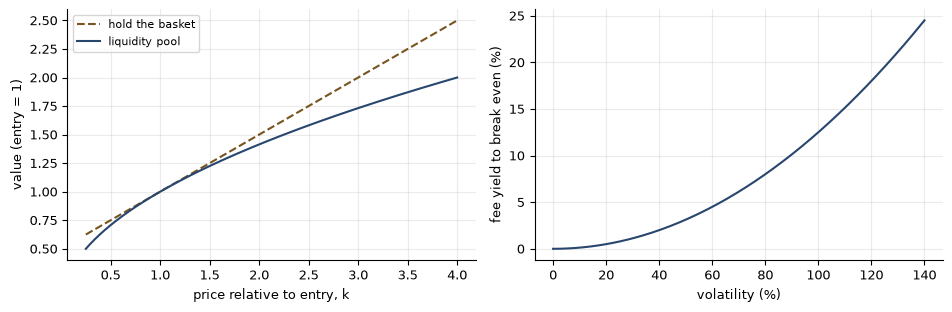

In [12]:
for k, hold_p, pool_p in ((0.25, 0.6250, 0.5000), (0.35, 0.6750, 0.5916), (2.5, 1.7500, 1.5811), (4.0, 2.5, 2.0)):
    show("figure: hold the basket at k = %.2f" % k, (1 + k) / 2, hold_p, 5e-5)
    show("figure: pool at k = %.2f" % k, sqrt(k), pool_p, 5e-5)
for vol, want in ((30, 1.13), (70, 6.13), (130, 21.13), (140, 24.50)):
    show("figure: fee yield at %d%% volatility (%%)" % vol, (vol / 100.0) ** 2 / 8 * 100, want, 5.01e-3)

ks = np.linspace(0.25, 4.0, 300)
vols = np.linspace(0.0, 1.4, 200)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2))
axes[0].plot(ks, (1 + ks) / 2, color=AMBER, ls="--", label="hold the basket")
axes[0].plot(ks, np.sqrt(ks), color=BLUE, label="liquidity pool")
axes[0].set_xlabel("price relative to entry, k")
axes[0].set_ylabel("value (entry = 1)")
axes[0].legend(fontsize=8)
axes[1].plot(100 * vols, 100 * vols ** 2 / 8, color=BLUE)
axes[1].set_xlabel("volatility (%)")
axes[1].set_ylabel("fee yield to break even (%)")
plt.tight_layout()
plt.show()

## 11. What the discount was pricing — Example 37.11

A stablecoin disclosed that 8.25% of its reserve, \$3.3 billion of about \$40 billion, sat at a failed bank. Its fair
value at a recovery $R$ on that deposit is $1 - 0.0825(1 - R)$. At its low the coin traded at 0.8774, a discount larger
than even a zero recovery explains.

In [13]:
EXPOSURE = 3.3 / 40.0
show("share of the reserve at the failed bank (%)", 100 * EXPOSURE, 8.25, 1e-9)
for R, fv_p, d_p in ((1.0, 1.0000, 0.00), (0.5, 0.9588, 4.13), (0.0, 0.9175, 8.25)):
    fv = 1 - EXPOSURE * (1 - R)
    show("fair value at %d%% recovery" % (100 * R), fv, fv_p, 5e-5)
    show("  discount (%)", 100 * (1 - fv), d_p, 5e-3)
show("observed discount at 0.8774 (%)", 100 * (1 - 0.8774), 12.3, 0.05)
show("points no recovery explains", 100 * ((1 - 0.8774) - EXPOSURE), 4.0, 0.05)

share of the reserve at the failed bank (%)                  8.2500   book        8.2500   ok
fair value at 100% recovery                                  1.0000   book        1.0000   ok
  discount (%)                                               0.0000   book        0.0000   ok
fair value at 50% recovery                                   0.9587   book        0.9588   ok
  discount (%)                                               4.1250   book        4.1300   ok
fair value at 0% recovery                                    0.9175   book        0.9175   ok
  discount (%)                                               8.2500   book        8.2500   ok
observed discount at 0.8774 (%)                             12.2600   book       12.3000   ok
points no recovery explains                                  4.0100   book        4.0000   ok


In [14]:
if BAD:
    print("%d figure(s) differ from the chapter:" % len(BAD))
    for b in BAD:
        print("   ", b)
else:
    print("every checked figure in the chapter reproduces.")

every checked figure in the chapter reproduces.
